# ShopperSense · 01 / Data and reasoning

**Question:** How well can recorded browsing-session characteristics identify sessions ending in a purchase, compared with always predicting no purchase?

One row is a session. Revenue maps explicitly to 0/1. These are historical session summaries, not proof of early-session availability. Run `python -m src.run_all` from the repository root first. This notebook executes structural inspection and training-only EDA through shared source code. It does not revise model choices using test results.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Start Jupyter from the repository root or notebooks/.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, SVG
from src.data import load_data
from src.config import FEATURES, NUMERIC, CATEGORICAL
def saved(name):
    return json.loads((ROOT / 'results' / name).read_text(encoding='utf-8'))
raw, frame = load_data(ROOT / 'data/raw/online_shoppers_intention.csv')
splits = saved('splits.json')
train_ids = splits['partitions']['train']['source_row_ids']
train = frame.loc[train_ids]


## Preserve the raw data and identify the file
The locally supplied download date is unknown. SHA-256 identifies the supplied bytes; no newly downloaded archive is assumed. Source: [UCI dataset 468](https://doi.org/10.24432/C5F88Q), Sakar & Kastro (2018), CC BY 4.0.

In [2]:
import hashlib
manifest = saved('data_manifest.json')
assert hashlib.sha256((ROOT / 'data/raw/online_shoppers_intention.csv').read_bytes()).hexdigest() == manifest['sha256']
display(pd.Series({k: manifest[k] for k in ['source_filename','sha256','rows','predictors','class_counts','provenance','license']}))
display(pd.Series(manifest['dtypes'], name='source dtype'))

source_filename                        online_shoppers_intention.csv
sha256             b3055ee355f59134d851d32641183cb4a8b45def7124d2...
rows                                                           12330
predictors                                                        17
class_counts                                 {'0': 10422, '1': 1908}
provenance         Supplied locally; original download date unkno...
license                                                    CC BY 4.0
dtype: object

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
Name: source dtype, dtype: str

## Whole-file structural audit
Duplicates are excess occurrences after the first row. A repeated observation is not automatically erroneous. Preserve all source rows and audit cross-partition overlap separately. Keep large durations and counts; a plotting transform is not a model transform.

In [3]:
from src.data import inspect_data
_, measured_quality = inspect_data(ROOT / 'data/raw/online_shoppers_intention.csv', raw, frame)
display(pd.DataFrame({k: measured_quality[k] for k in ['missing_by_column','nonfinite_by_numeric_column','negative_by_numeric_column']}))
display(pd.Series({k: measured_quality[k] for k in ['complete_duplicate_rows','identical_predictor_extra_rows','unexpected_categories','source_expectations_match']}))
display(pd.DataFrame(measured_quality['numeric_summary']))

,missing_by_column,nonfinite_by_numeric_column,negative_by_numeric_column
Administrative,0,0.0,0.0
Administrative_Duration,0,0.0,0.0
Informational,0,0.0,0.0
Informational_Duration,0,0.0,0.0
ProductRelated,0,0.0,0.0
ProductRelated_Duration,0,0.0,0.0
BounceRates,0,0.0,0.0
ExitRates,0,0.0,0.0
PageValues,0,0.0,0.0
SpecialDay,0,0.0,0.0


complete_duplicate_rows                                                         125
identical_predictor_extra_rows                                                  125
unexpected_categories             {'Month': [], 'OperatingSystems': [], 'Browser...
source_expectations_match                                                      True
dtype: object

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Weekend
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,0.232603
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.422509
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,0.000000
95%,9.000000,348.266369,3.000000,195.000000,109.000000,4300.289077,0.200000,0.200000,38.160528,0.600000,1.000000
99%,14.000000,830.587041,6.000000,716.390000,221.000000,8701.142697,0.200000,0.200000,85.498490,1.000000,1.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,1.000000


## Split before exploring
First hold out 15% test, then split 15/85 of the remainder as validation. Both calls stratify Revenue with random_state=42. ID arrays cover the file exactly once. The CV preprocessing is fitted within each training fold.

In [4]:
from src.data import split_rows
parts, repeat = split_rows(frame, manifest['sha256'])
assert repeat == splits
display(pd.DataFrame({p: {'sessions': len(ids), 'purchases': int(frame.loc[ids].Revenue.sum())} for p, ids in parts.items()}).T)
display(pd.DataFrame(saved('quality.json')['cross_partition_duplicate_audit']['pairs']))

,sessions,purchases
train,8630,1336
validation,1850,286
test,1850,286


,a,b,shared_vectors,a_rows,b_rows,a_purchases,b_purchases
0,train,validation,29,48,32,0,0
1,train,test,13,30,18,0,0
2,validation,test,7,8,12,0,0


## Class imbalance: a reference, not a solution
Whole-file counts describe the supplied source. Always predicting no purchase can have high accuracy while missing every buyer; AP, purchase recall and F1 are more revealing.

Revenue
No purchase    10422
Purchase        1908
Name: count, dtype: int64

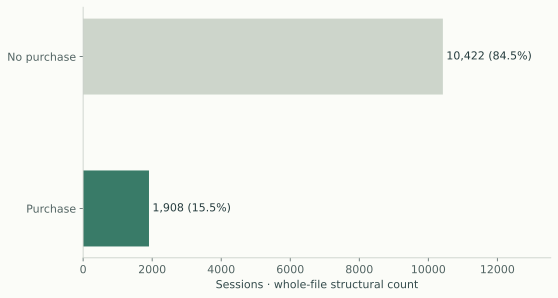

In [5]:
display(frame.Revenue.value_counts().rename(index={0: 'No purchase', 1: 'Purchase'}))
display(SVG(filename=str(ROOT / 'results/figures/class_balance.svg')))

## Training-only visitor rates and browsing intensity
Show numerators and denominators, and avoid claims about motives. The `Other` category has little support. Plot log(1 + pages) to make skew visible; normalization is within target class.

,sessions,purchases,purchase_rate
VisitorType,,,
New_Visitor,1162,293,0.252151
Other,63,10,0.158730
Returning_Visitor,7405,1033,0.139500


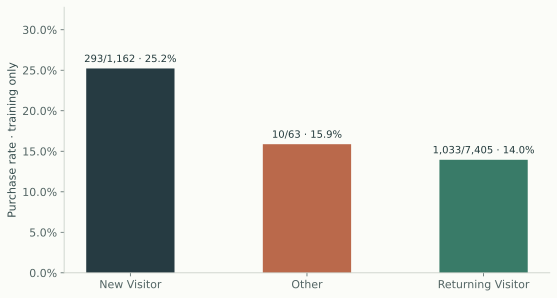

,size,median,max
Revenue,,,
0,7294,16.0,705
1,1336,29.0,501


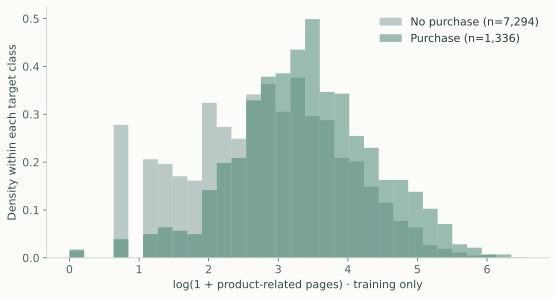

In [6]:
display(train.groupby('VisitorType').Revenue.agg(sessions='size', purchases='sum', purchase_rate='mean'))
display(SVG(filename=str(ROOT / 'results/figures/visitor_rates.svg')))
display(train.groupby('Revenue').ProductRelated.agg(['size','median','max']))
display(SVG(filename=str(ROOT / 'results/figures/browsing_intensity.svg')))

## Preprocessing rationale
Numeric training medians retain rows if missing values occur; fixed categorical missing tokens preserve missingness. One-hot encoding prevents ordered interpretation of numeric category codes, with unknown categories ignored. Logistic Regression uses numeric StandardScaler; trees keep the original scale. Weekend is explicit binary. Revenue and row IDs are not inputs. No SMOTE, class weights, or outlier deletion.

In [7]:
from src.preprocessing import preprocessor
display(preprocessor(scale=True))
assert 'Revenue' not in FEATURES and 'source_row_id' not in FEATURES
assert 'PageValues' not in preprocessor(without_pagevalues=True).transformers[0][2]
display(pd.DataFrame({'training_skew': train[NUMERIC].skew(), 'training_p99': train[NUMERIC].quantile(.99)}))

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

,training_skew,training_p99
Administrative,1.956163,14.000000
Administrative_Duration,5.354614,878.552667
Informational,4.360448,6.000000
Informational_Duration,7.493201,753.135000
ProductRelated,4.103057,212.420000
ProductRelated_Duration,5.254912,8593.002949
BounceRates,2.936286,0.200000
ExitRates,2.133487,0.200000
PageValues,6.321479,85.498490
SpecialDay,3.317349,1.000000


## Availability limitation
PageValues is an analytics measure connected to pages visited before transactions. Its precise construction timing in this file is unresolved; do not assert proven leakage. Prespecify the same-row no-PageValues LR and RF experiment. Remaining counts, durations, bounce and exit summaries may also be unavailable at an early decision point. These observations are associations within one historical source, without price/quality preferences or causal outcomes.